# 📘 7.3 Euler's Method

### Advancing an ODE state using its current local rate

Notebook 7.2 formulated the thermal initial-value problem

$$
\frac{dT}{dt}=\frac{P(t)-H(T-T_\infty)}{C},
\qquad T(t_0)=T_0.
$$

When an analytical solution is unavailable, a numerical method constructs an
approximate state at a sequence of time coordinates. **Explicit Euler's method** is
the simplest time-marching method: evaluate the current derivative, assume that slope
remains constant over one finite step, and advance the state.

Euler's method is easy to inspect and implement. It also exposes the central ideas
used by more capable ODE solvers: state updates, step size, accumulated error,
stability, input discontinuities and validation against data.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* derive the explicit Euler update from a local tangent approximation;
* identify every term in $y_{n+1}=y_n+h f(t_n,y_n)$;
* calculate the first Euler steps of an engineering IVP manually;
* implement a reusable Euler solver for a scalar first-order ODE;
* distinguish the ODE model, numerical method, step size and output coordinates;
* explain local truncation error $O(h^2)$ and global error $O(h)$;
* verify first-order convergence using a known reference solution;
* apply the Euler stability condition to a decaying mode;
* handle a discontinuous prescribed input without stepping across it blindly;
* separate measurement coordinates from internal solver steps; and
* explain how numerical error can bias calibrated ODE parameters.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of numerical analysis and machine
  learning tools for engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools
  to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common
  engineering problems, and evaluate performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* SciPy — [`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)
* SciPy User Guide — [Ordinary differential equations](https://docs.scipy.org/doc/scipy/tutorial/integrate.html#ordinary-differential-equations-solve-ivp)
* NumPy — [`numpy.interp`](https://numpy.org/doc/stable/reference/generated/numpy.interp.html)


## 📂 7.3.0 How to use this notebook

Run every code cell in order. No editing or input is required. Use the optional
control near the end to explore step size after reviewing the static examples.

> ### 🧭 Theory preface
> Euler's formula is short, but using it responsibly requires more than substituting
> numbers. Concentrate on where the slope is evaluated, what interval that slope is
> assumed to represent, and how step size affects both accuracy and stability.
>
> The exact thermal solution is retained as a teaching reference. In a real project,
> convergence across numerical settings and comparison with independent data must
> replace access to a hidden exact trajectory.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

BLUE = "#006DAE"
ORANGE = "#E57200"
GREEN = "#00843D"
RED = "#C8102E"
PURPLE = "#7A52A1"

MASS_KG = 2.0
CP_J_KG_K = 900.0
C_J_K = MASS_KG*CP_J_KG_K
H_W_K = 7.5
AMBIENT_C = 22.0
HEATER_W = 150.0
INITIAL_C = 22.0
TAU_S = C_J_K/H_W_K
EQUILIBRIUM_C = AMBIENT_C + HEATER_W/H_W_K

def thermal_rhs(time_s, temperature_c, power_w=HEATER_W,
                capacitance_j_k=C_J_K, conductance_w_k=H_W_K,
                ambient_c=AMBIENT_C):
    '''Return dT/dt [K/s] for the lumped thermal model.'''
    return (
        power_w-conductance_w_k*(temperature_c-ambient_c)
    )/capacitance_j_k

def thermal_exact(time_s, initial_c=INITIAL_C, power_w=HEATER_W,
                  capacitance_j_k=C_J_K, conductance_w_k=H_W_K,
                  ambient_c=AMBIENT_C, initial_time_s=0.0):
    '''Exact constant-input thermal trajectory used for validation.'''
    time_s = np.asarray(time_s, dtype=float)
    equilibrium_c = ambient_c + power_w/conductance_w_k
    tau_s = capacitance_j_k/conductance_w_k
    return equilibrium_c + (initial_c-equilibrium_c)*np.exp(
        -(time_s-initial_time_s)/tau_s
    )

print(f"Baseline equilibrium = {EQUILIBRIUM_C:.1f} °C")
print(f"Baseline time constant = {TAU_S:.1f} s")


Baseline equilibrium = 42.0 °C
Baseline time constant = 240.0 s


### 📖 Core language for 7.3

| Term | Meaning |
|---|---|
| $t_n$ | Current numerical time coordinate at step index $n$ |
| $y_n$ | Numerical approximation to the state $y(t_n)$ |
| $f(t_n,y_n)$ | ODE right-hand side evaluated at the current numerical point |
| $h=t_{n+1}-t_n$ | Time-step size [s] |
| $y_{n+1}$ | Numerical state after one update |
| **Time step** | One internal numerical advance, not necessarily one measurement interval |
| **Trajectory** | The sequence of numerical coordinates and states |

The subscript $n$ is a step index, not a physical exponent. Euler's method generates
approximations $y_n$; it does not convert the continuous state $y(t)$ into a new model.


## 📂 7.3.1 From a local derivative to a finite step

At a known point $(t_n,y_n)$, the ODE supplies the local slope

$$
\left.\frac{dy}{dt}\right|_{(t_n,y_n)}=f(t_n,y_n).
$$

The tangent-line approximation over a short interval $h$ is

$$
y(t_n+h)\approx y_n+h f(t_n,y_n).
$$

Euler's method uses this tangent prediction as the next numerical state. The slope is
evaluated only at the **left-hand end** of the step and treated as constant throughout
that step.


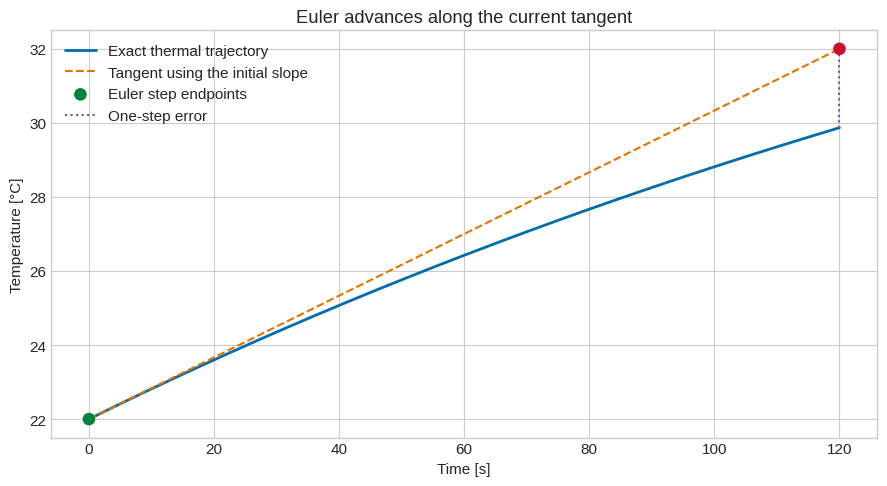

In [ ]:
t_n = 0.0
temperature_n = INITIAL_C
h_demo = 120.0
slope_n = thermal_rhs(t_n, temperature_n)
temperature_euler = temperature_n + h_demo*slope_n

local_times = np.linspace(0.0, h_demo, 250)
tangent_temperature = temperature_n + slope_n*local_times
exact_temperature = thermal_exact(local_times)

plt.figure(figsize=(9, 5))
plt.plot(local_times, exact_temperature, color=BLUE, linewidth=2,
         label="Exact thermal trajectory")
plt.plot(local_times, tangent_temperature, color=ORANGE, linestyle="--",
         label="Tangent using the initial slope")
plt.scatter([t_n, h_demo], [temperature_n, temperature_euler],
            color=[GREEN, RED], s=65, zorder=4,
            label="Euler step endpoints")
plt.vlines(h_demo, thermal_exact(h_demo), temperature_euler,
           color=PURPLE, linestyle=":", label="One-step error")
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("Euler advances along the current tangent")
plt.legend()
plt.tight_layout()
plt.show()


The true thermal rate decreases as temperature rises and heat loss increases. Euler's
method does not account for that rate change inside this step, so the initial tangent
overpredicts the temperature at 120 s.


## 📂 7.3.2 The explicit Euler update

For the first-order IVP

$$
\frac{dy}{dt}=f(t,y),\qquad y(t_0)=y_0,
$$

explicit Euler uses

$$
\boxed{y_{n+1}=y_n+h f(t_n,y_n)},
\qquad
t_{n+1}=t_n+h.
$$

For the thermal state this becomes

$$
T_{n+1}=T_n+
h\frac{P(t_n)-H(T_n-T_\infty)}{C}.
$$

The update is **explicit** because every quantity on the right-hand side is already
known at step $n$. An implicit method would involve the unknown next state on the
right-hand side and require an equation solve.


### Unit check for the update

$$
T_{n+1}\ [^\circ\mathrm{C}]
=T_n\ [^\circ\mathrm{C}]
+h\ [\mathrm{s}]\,
f(t_n,T_n)\ [\mathrm{K/s}].
$$

A temperature **change** in kelvin has the same numerical magnitude as a temperature
change in degrees Celsius, so the update is dimensionally consistent.


## 📂 7.3.3 Calculate the first thermal steps

With $h=60$ s and $T_0=22^\circ$C:

$$
f(t_0,T_0)=
\frac{150-7.5(22-22)}{1800}
=0.08333\ \mathrm{K/s},
$$

so

$$
T_1=22+60(0.08333)=27.0^\circ\mathrm{C}.
$$

At the new state, heat loss is larger and the next rate is smaller. Euler must
re-evaluate the ODE before every update.


In [ ]:
h_manual = 60.0
manual_times = [0.0]
manual_temperatures = [INITIAL_C]

print(" n   t_n [s]   T_n [°C]   f(t_n,T_n) [K/s]   T_(n+1) [°C]")
for n in range(4):
    current_time = manual_times[-1]
    current_temperature = manual_temperatures[-1]
    current_rate = thermal_rhs(current_time, current_temperature)
    next_temperature = current_temperature + h_manual*current_rate
    print(f" {n:1d}   {current_time:7.1f}   {current_temperature:8.3f}   "
          f"{current_rate:17.5f}   {next_temperature:12.3f}")
    manual_times.append(current_time+h_manual)
    manual_temperatures.append(next_temperature)

print("\nAfter four steps:")
print(f"Euler T(240 s) = {manual_temperatures[-1]:.3f} °C")
print(f"Exact T(240 s) = {thermal_exact(240.0):.3f} °C")


 n   t_n [s]   T_n [°C]   f(t_n,T_n) [K/s]   T_(n+1) [°C]
 0       0.0     22.000             0.08333         27.000
 1      60.0     27.000             0.06250         30.750
 2     120.0     30.750             0.04688         33.562
 3     180.0     33.562             0.03516         35.672

After four steps:
Euler T(240 s) = 35.672 °C
Exact T(240 s) = 34.642 °C


### 🧠 What should you notice?

Each row uses the state produced by the previous row. A small one-step discrepancy
therefore affects later slopes and accumulates through the trajectory. Reusing the
initial slope for every row would not be Euler's method; it would extend one tangent
indefinitely.


## 📂 7.3.4 A reusable scalar Euler solver

A robust teaching implementation should:

* accept the ODE right-hand-side function separately from the method;
* retain both time and state coordinates;
* avoid stepping beyond the requested final time; and
* shorten the last step when the interval is not an exact multiple of $h$.

Keeping the model and method separate allows the same Euler routine to solve other
first-order scalar ODEs.


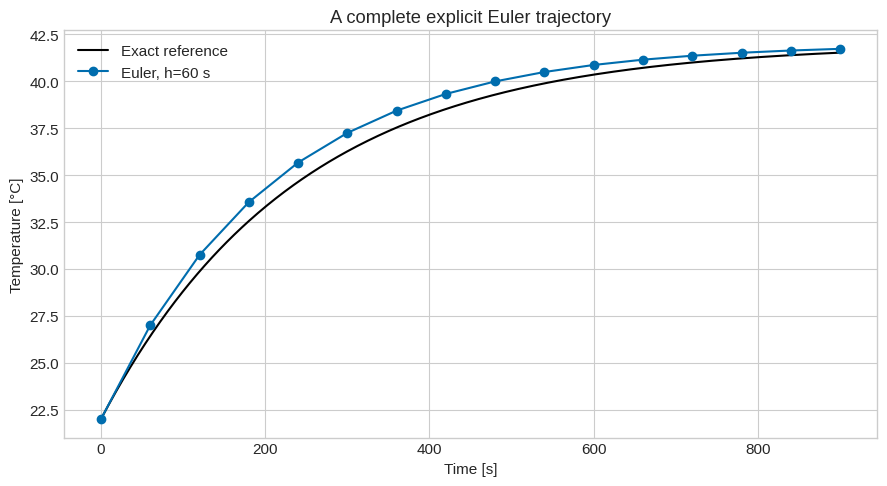

In [ ]:
def euler_scalar(rhs, time_span, initial_state, step_size):
    '''Explicit Euler for one scalar first-order IVP.'''
    start_time, final_time = map(float, time_span)
    if final_time <= start_time:
        raise ValueError("final time must be greater than start time")
    if step_size <= 0:
        raise ValueError("step size must be positive")

    times = [start_time]
    states = [float(initial_state)]
    while times[-1] < final_time:
        h_n = min(step_size, final_time-times[-1])
        rate_n = rhs(times[-1], states[-1])
        states.append(states[-1]+h_n*rate_n)
        times.append(times[-1]+h_n)
    return np.asarray(times), np.asarray(states)

time_euler, temperature_euler = euler_scalar(
    thermal_rhs, (0.0, 900.0), INITIAL_C, step_size=60.0
)

plt.figure(figsize=(9, 5))
dense_time = np.linspace(0.0, 900.0, 500)
plt.plot(dense_time, thermal_exact(dense_time), color="black",
         label="Exact reference")
plt.plot(time_euler, temperature_euler, "o-", color=BLUE,
         label="Euler, h=60 s")
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("A complete explicit Euler trajectory")
plt.legend()
plt.tight_layout()
plt.show()


## 📂 7.3.5 Step size controls cost and accuracy

A smaller $h$ updates the slope more frequently and usually reduces discretisation
error for a smooth, stable problem. It also requires more right-hand-side evaluations.
Step size should be studied relative to the system time scale, not chosen only because
it produces a visually smooth line.


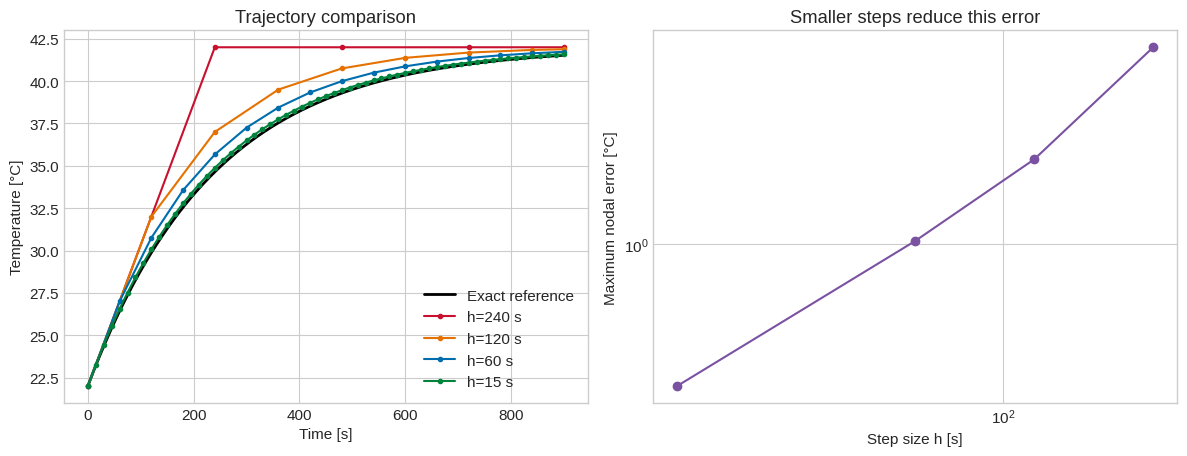

 h [s]   steps   maximum nodal error [°C]
   240       4                    7.35759
   120       8                    2.35759
    60      15                    1.02946
    15      60                    0.23611


In [ ]:
step_sizes_demo = [240.0, 120.0, 60.0, 15.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].plot(dense_time, thermal_exact(dense_time), color="black",
             linewidth=2, label="Exact reference")

rows = []
for step, color in zip(step_sizes_demo, [RED, ORANGE, BLUE, GREEN]):
    t_num, T_num = euler_scalar(
        thermal_rhs, (0.0, 900.0), INITIAL_C, step
    )
    exact_at_nodes = thermal_exact(t_num)
    max_error = np.max(np.abs(T_num-exact_at_nodes))
    rows.append((step, len(t_num)-1, max_error))
    axes[0].plot(t_num, T_num, "o-", ms=3, color=color,
                 label=f"h={step:.0f} s")

axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Temperature [°C]")
axes[0].set_title("Trajectory comparison")
axes[0].legend()

axes[1].loglog([r[0] for r in rows], [r[2] for r in rows], "o-", color=PURPLE)
axes[1].set_xlabel("Step size h [s]")
axes[1].set_ylabel("Maximum nodal error [°C]")
axes[1].set_title("Smaller steps reduce this error")
fig.tight_layout()
plt.show()

print(" h [s]   steps   maximum nodal error [°C]")
for step, steps, error in rows:
    print(f" {step:5.0f}   {steps:5d}   {error:24.5f}")


The 240 s step equals the thermal time constant. Although the trajectory reaches the
equilibrium quickly, that visual behaviour is not an accurate representation of the
exponential transient. A numerically convenient answer can still distort response
time, peak values or threshold-crossing times.


## 📂 7.3.6 Local and global truncation error

Taylor expansion of the exact solution gives

$$
y(t_n+h)=y(t_n)+h y'(t_n)+\frac{h^2}{2}y''(\xi_n),
$$

for some coordinate $\xi_n$ inside the step. Euler retains the first two terms and
omits a leading term proportional to $h^2$.

* **Local truncation error:** the error introduced by one Euler step starting from
  the exact state; it is $O(h^2)$.
* **Global truncation error:** the accumulated state error after approximately
  $(t_f-t_0)/h$ steps; for a stable smooth problem it is $O(h)$.

Euler is therefore called a **first-order method**. This refers to global convergence,
not the order of the differential equation.


## 📂 7.3.7 Verify first-order convergence

If the global error behaves as $E(h)\approx C_E h^p$, the observed order between
successive step sizes is

$$
p_{\mathrm{obs}}=
\frac{\log[E(h_2)/E(h_1)]}{\log(h_2/h_1)}.
$$

We use the maximum absolute error at Euler nodes. The exact solution is available only
as a teaching reference; later, differences between refined numerical solutions can
provide practical convergence evidence.


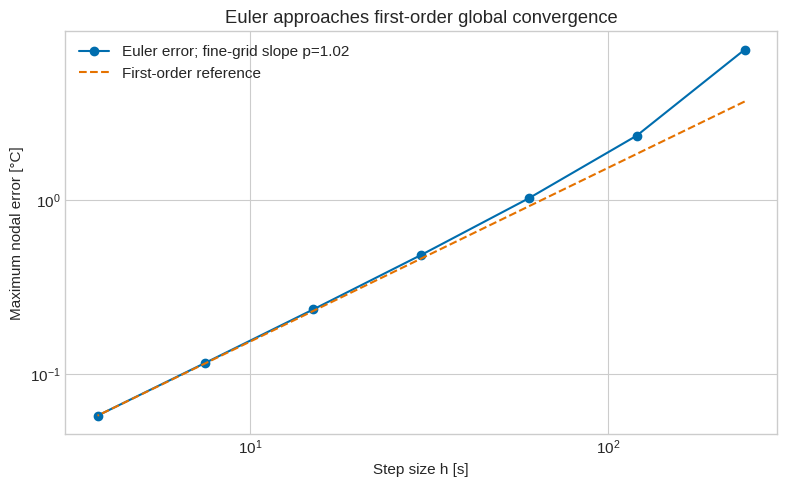

Successive observed orders: [1.642 1.195 1.085 1.04  1.019 1.01 ]


In [ ]:
convergence_steps = 240.0/2**np.arange(0, 7)
convergence_errors = []
evaluation_counts = []

for step in convergence_steps:
    t_num, T_num = euler_scalar(
        thermal_rhs, (0.0, 960.0), INITIAL_C, step
    )
    convergence_errors.append(
        np.max(np.abs(T_num-thermal_exact(t_num)))
    )
    evaluation_counts.append(len(t_num)-1)

convergence_errors = np.asarray(convergence_errors)
observed_orders = np.log(
    convergence_errors[1:]/convergence_errors[:-1]
)/np.log(convergence_steps[1:]/convergence_steps[:-1])
fitted_order = np.polyfit(
    np.log(convergence_steps[-4:]),
    np.log(convergence_errors[-4:]), 1
)[0]

plt.figure(figsize=(8, 5))
plt.loglog(convergence_steps, convergence_errors, "o-", color=BLUE,
           label=f"Euler error; fine-grid slope p={fitted_order:.2f}")
reference = convergence_errors[-1]*(convergence_steps/convergence_steps[-1])
plt.loglog(convergence_steps, reference, "--", color=ORANGE,
           label="First-order reference")
plt.xlabel("Step size h [s]")
plt.ylabel("Maximum nodal error [°C]")
plt.title("Euler approaches first-order global convergence")
plt.legend()
plt.tight_layout()
plt.show()

print("Successive observed orders:", np.round(observed_orders, 3))


### 🧠 Interpretation

The observed order approaches one as the grid is refined. Coarse steps may lie outside
the asymptotic regime, so one comparison is insufficient. Convergence demonstrates
numerical consistency with the reference for this model; it does not validate the
heat-loss assumptions or fitted parameters.


## 📂 7.3.8 Stability: errors must not grow without physical cause

Consider the decay test equation

$$
\frac{de}{dt}=-\lambda e,
\qquad \lambda>0,
$$

whose exact solution decays toward zero. Euler gives

$$
e_{n+1}=e_n-h\lambda e_n=(1-h\lambda)e_n.
$$

The factor

$$
G=1-h\lambda
$$

is the Euler amplification factor. Numerical errors decay only when

$$
|G|<1
\quad\Longleftrightarrow\quad
0<h\lambda<2.
$$

Stability is a property of the numerical method, step size and problem dynamics
together. A method is not simply “stable” without that context.


## 📂 7.3.9 Thermal interpretation of Euler stability

Define the deviation from equilibrium

$$
e(t)=T(t)-T_{\mathrm{eq}}.
$$

Substitution into the constant-input thermal ODE gives

$$
\frac{de}{dt}=-\frac{H}{C}e=-\frac{1}{\tau}e.
$$

Thus $\lambda=1/\tau$ and Euler requires

$$
0<h<2\tau=480\ \mathrm{s}
$$

for asymptotic decay. This stability limit is much larger than a step size we would
choose for accurate transient prediction.


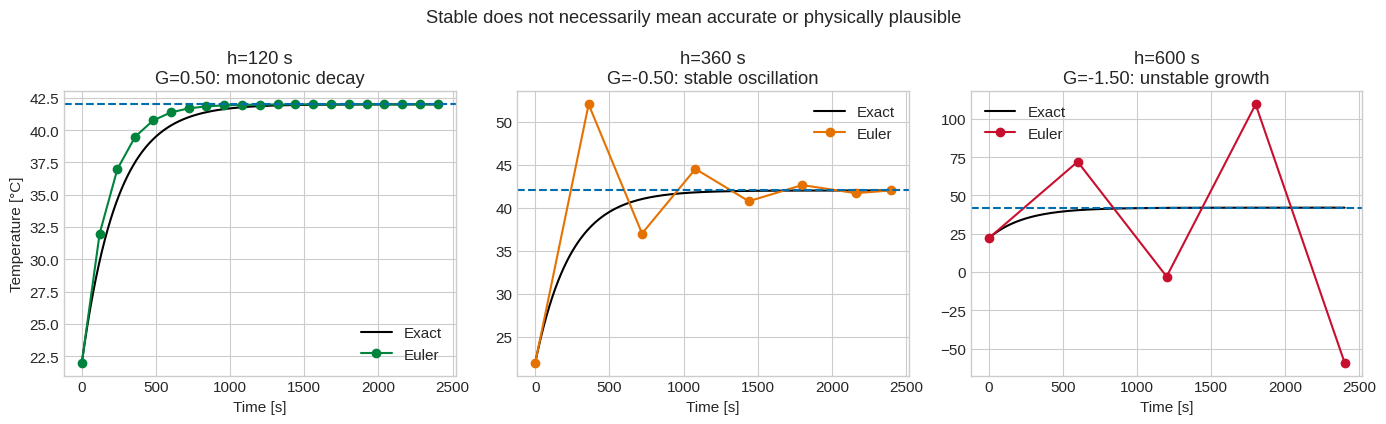

In [ ]:
stability_steps = [120.0, 360.0, 600.0]
labels = [
    "G=0.50: monotonic decay",
    "G=-0.50: stable oscillation",
    "G=-1.50: unstable growth",
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=False)
for ax, step, label, color in zip(
    axes, stability_steps, labels, [GREEN, ORANGE, RED]
):
    t_num, T_num = euler_scalar(
        thermal_rhs, (0.0, 2400.0), INITIAL_C, step
    )
    exact_t = np.linspace(0.0, 2400.0, 500)
    ax.plot(exact_t, thermal_exact(exact_t), color="black", label="Exact")
    ax.plot(t_num, T_num, "o-", color=color, label="Euler")
    ax.axhline(EQUILIBRIUM_C, color=BLUE, linestyle="--")
    ax.set_xlabel("Time [s]")
    ax.set_title(f"h={step:.0f} s\n{label}")
    ax.legend()
axes[0].set_ylabel("Temperature [°C]")
fig.suptitle("Stable does not necessarily mean accurate or physically plausible")
fig.tight_layout()
plt.show()


The 360 s result converges toward equilibrium because $|G|<1$, but it alternates
above and below equilibrium even though the exact heating response is monotonic. It
is mathematically stable yet physically poor. The 600 s result creates growing
oscillations in a system whose true response decays.


## 📂 7.3.10 Discontinuous inputs require aligned steps

If the heater switches off at 600 s, the right-hand side changes discontinuously.
An Euler step beginning before 600 s uses the left-end power over its entire interval.
If that step crosses the switch, it applies the old input for too long.

A defensible approach ends one integration segment exactly at the known switching
time, then restarts with the updated input and the final state from the first segment.


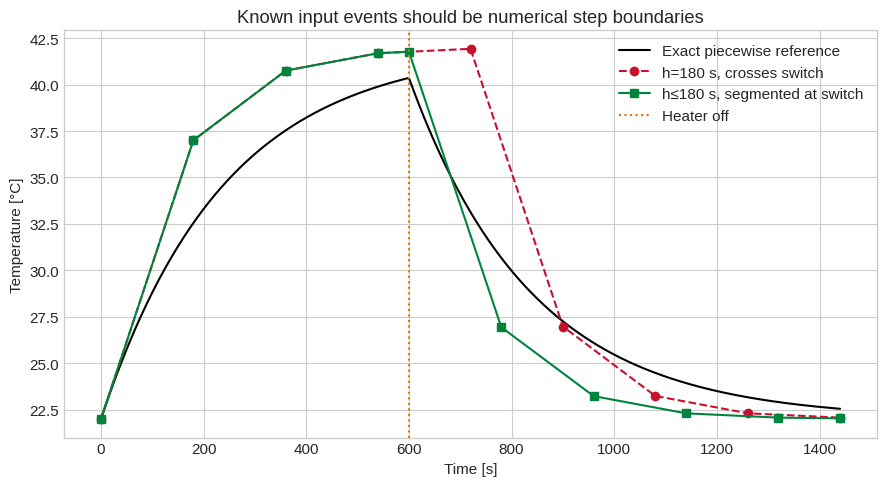

In [ ]:
SWITCH_TIME_S = 600.0

def switched_rhs(time_s, temperature_c):
    power_w = HEATER_W if time_s < SWITCH_TIME_S else 0.0
    return thermal_rhs(time_s, temperature_c, power_w=power_w)

temperature_at_switch = thermal_exact(SWITCH_TIME_S)

def switched_exact(time_s):
    time_s = np.asarray(time_s, dtype=float)
    heating = thermal_exact(np.minimum(time_s, SWITCH_TIME_S))
    cooling = thermal_exact(
        time_s,
        initial_c=temperature_at_switch,
        power_w=0.0,
        initial_time_s=SWITCH_TIME_S,
    )
    return np.where(time_s <= SWITCH_TIME_S, heating, cooling)

# One uninterrupted grid crosses the event because 600/180 is not an integer.
t_cross, T_cross = euler_scalar(
    switched_rhs, (0.0, 1440.0), INITIAL_C, 180.0
)

# Segmented calculation forces a step endpoint at the switching time.
t_on, T_on = euler_scalar(
    switched_rhs, (0.0, SWITCH_TIME_S), INITIAL_C, 180.0
)
t_off, T_off = euler_scalar(
    switched_rhs, (SWITCH_TIME_S, 1440.0), T_on[-1], 180.0
)
t_aligned = np.concatenate([t_on, t_off[1:]])
T_aligned = np.concatenate([T_on, T_off[1:]])

t_exact_switch = np.linspace(0.0, 1440.0, 600)
plt.figure(figsize=(9, 5))
plt.plot(t_exact_switch, switched_exact(t_exact_switch), color="black",
         label="Exact piecewise reference")
plt.plot(t_cross, T_cross, "o--", color=RED,
         label="h=180 s, crosses switch")
plt.plot(t_aligned, T_aligned, "s-", color=GREEN,
         label="h≤180 s, segmented at switch")
plt.axvline(SWITCH_TIME_S, color=ORANGE, linestyle=":", label="Heater off")
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("Known input events should be numerical step boundaries")
plt.legend()
plt.tight_layout()
plt.show()


Event alignment removes one avoidable error source, but the remaining 180 s steps are
still coarse. Handling a discontinuity correctly does not guarantee accurate dynamics
between events.


## 📂 7.3.11 Solver steps are not measurement data points

Experimental temperatures may be recorded at times $t_i^{\mathrm{meas}}$, while a
numerical solver advances through internal coordinates $t_n^{\mathrm{step}}$.
These sets do not need to be equal.

* Measurement times are determined by sensor logging and experimental design.
* Solver steps are selected to satisfy numerical accuracy and stability needs.
* Model predictions are then evaluated or interpolated at the measurement times for
  residual calculation.

Choosing $h$ equal to the data spacing merely because both are measured in seconds is
not a numerical justification.


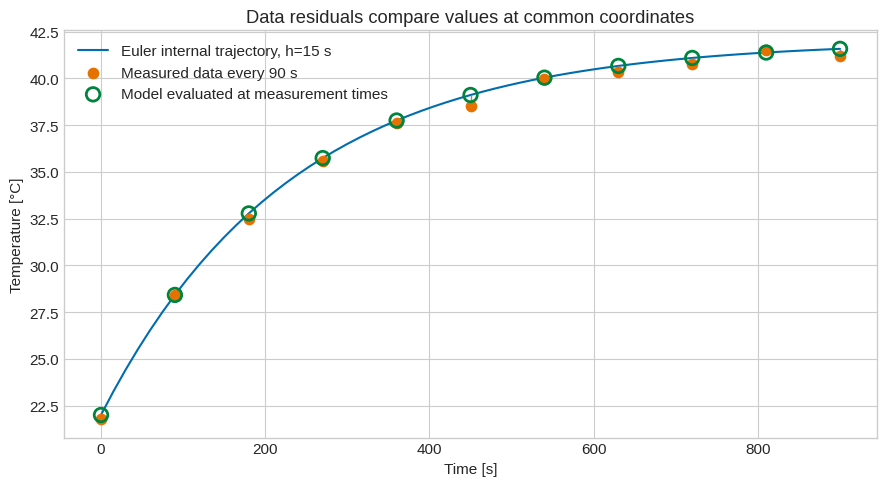

In [ ]:
rng = np.random.default_rng(73)
measurement_times = np.arange(0.0, 901.0, 90.0)
measured_temperature = thermal_exact(measurement_times) + rng.normal(
    0.0, 0.20, measurement_times.size
)

internal_time, internal_temperature = euler_scalar(
    thermal_rhs, (0.0, 900.0), INITIAL_C, 15.0
)
prediction_at_measurements = np.interp(
    measurement_times, internal_time, internal_temperature
)

plt.figure(figsize=(9, 5))
plt.plot(internal_time, internal_temperature, color=BLUE, linewidth=1.5,
         label="Euler internal trajectory, h=15 s")
plt.scatter(measurement_times, measured_temperature, color=ORANGE, s=55,
            label="Measured data every 90 s", zorder=4)
plt.scatter(measurement_times, prediction_at_measurements, facecolors="none",
            edgecolors=GREEN, s=95, linewidths=2,
            label="Model evaluated at measurement times", zorder=5)
for t_m, y_m, p_m in zip(
    measurement_times, measured_temperature, prediction_at_measurements
):
    plt.vlines(t_m, min(y_m, p_m), max(y_m, p_m), color="0.55", linewidth=1)
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("Data residuals compare values at common coordinates")
plt.legend()
plt.tight_layout()
plt.show()


The vertical segments are data residuals. The blue internal Euler points support the
numerical calculation but are not additional experimental observations.


## 📂 7.3.12 Coarse numerical methods can bias trained parameters

During ODE calibration, an optimizer repeatedly generates a trajectory and compares
it with data. If Euler's step is too large, the optimizer may change physical
parameters to compensate for discretisation error.

We now fit $C$ and $H$ to the same synthetic data using two Euler settings. The model
structure and measurements are unchanged; only the internal numerical step differs.


Trajectory used in fit     fitted C [J/K]   fitted H [W/K]
Analytical reference               1791.0            7.502
Euler h=  180 s                    2450.0            7.581
Euler h=   15 s                    1847.8            7.502


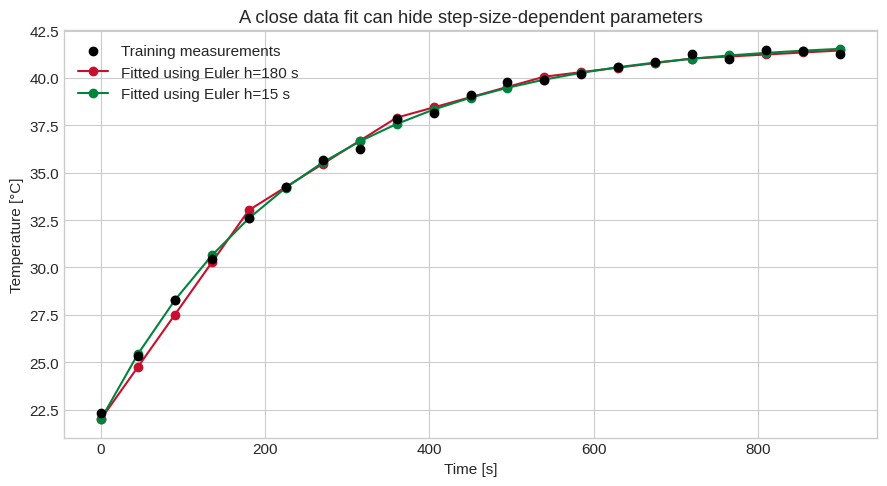

In [ ]:
calibration_times = np.arange(0.0, 901.0, 45.0)
rng_fit = np.random.default_rng(730)
calibration_data = thermal_exact(calibration_times) + rng_fit.normal(
    0.0, 0.15, calibration_times.size
)

def euler_prediction(parameters, internal_step):
    capacitance_j_k, conductance_w_k = parameters

    def candidate_rhs(time_s, temperature_c):
        return thermal_rhs(
            time_s, temperature_c,
            capacitance_j_k=capacitance_j_k,
            conductance_w_k=conductance_w_k,
        )

    t_num, T_num = euler_scalar(
        candidate_rhs,
        (calibration_times[0], calibration_times[-1]),
        INITIAL_C,
        internal_step,
    )
    return np.interp(calibration_times, t_num, T_num)

fitted_cases = []
for internal_step in [180.0, 15.0]:
    result = least_squares(
        lambda parameters: (
            euler_prediction(parameters, internal_step)-calibration_data
        )/0.15,
        x0=np.array([1500.0, 9.0]),
        bounds=([300.0, 1.0], [5000.0, 30.0]),
        x_scale="jac",
    )
    fitted_cases.append((internal_step, *result.x))

exact_fit = least_squares(
    lambda parameters: (
        thermal_exact(
            calibration_times,
            capacitance_j_k=parameters[0],
            conductance_w_k=parameters[1],
        )-calibration_data
    )/0.15,
    x0=np.array([1500.0, 9.0]),
    bounds=([300.0, 1.0], [5000.0, 30.0]),
    x_scale="jac",
)

print("Trajectory used in fit     fitted C [J/K]   fitted H [W/K]")
print(f"Analytical reference       {exact_fit.x[0]:14.1f}   {exact_fit.x[1]:14.3f}")
for step, fitted_c, fitted_h in fitted_cases:
    print(f"Euler h={step:5.0f} s            {fitted_c:14.1f}   {fitted_h:14.3f}")

plt.figure(figsize=(9, 5))
plt.scatter(calibration_times, calibration_data, color="black",
            label="Training measurements", zorder=4)
colors = [RED, GREEN]
for (step, fitted_c, fitted_h), color in zip(fitted_cases, colors):
    prediction = euler_prediction((fitted_c, fitted_h), step)
    plt.plot(calibration_times, prediction, "o-", color=color,
             label=f"Fitted using Euler h={step:.0f} s")
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.title("A close data fit can hide step-size-dependent parameters")
plt.legend()
plt.tight_layout()
plt.show()


### 🧠 Calibration interpretation

The coarse Euler trajectory can fit the data by moving $C$ or $H$ away from their
physical generating values. Therefore:

1. establish numerical convergence before trusting fitted parameters;
2. make solver error small compared with measurement uncertainty;
3. hold the numerical settings fixed when comparing parameter candidates; and
4. validate the fitted model on an independent experiment without refitting.

Parameter optimisation does not protect against a poor numerical method.


## 📂 7.3.13 Final-time and step-count details

If $(t_f-t_0)/h$ is not an integer, repeatedly adding $h$ can step beyond $t_f$.
The helper in this notebook uses

$$
h_n=\min(h,\,t_f-t_n)
$$

so the final step may be shorter. Report the actual time grid rather than assuming
every interval has the nominal size. For known events, segment the integration so an
event coordinate is also represented exactly.


In [ ]:
t_short, T_short = euler_scalar(
    thermal_rhs, (0.0, 1000.0), INITIAL_C, 120.0
)
actual_steps = np.diff(t_short)
print("Nominal step: 120 s")
print("Actual steps:", actual_steps)
print(f"Final coordinate: {t_short[-1]:.1f} s")
print(f"Final step: {actual_steps[-1]:.1f} s")


Nominal step: 120 s
Actual steps: [120. 120. 120. 120. 120. 120. 120. 120.  40.]
Final coordinate: 1000.0 s
Final step: 40.0 s


## 📂 7.3.14 Limitations and engineering checks

Before accepting an Euler result, check:

* **Units:** does $h f$ have the same units as the state?
* **Initial condition:** does the first numerical value equal the specified state?
* **Direction:** does the first update agree with the expected sign of the balance?
* **Resolution:** do important outputs converge as $h$ decreases?
* **Stability:** is the step inside the relevant stability limit?
* **Physical constraints:** are positivity, bounds and monotonic behaviour preserved?
* **Inputs and events:** are discontinuities represented at step boundaries?
* **Data comparison:** are predictions and observations compared at common times?
* **Calibration:** are fitted parameters insensitive to further numerical refinement?

Euler is valuable for learning, quick estimates and some low-risk models. It is often
inefficient when high accuracy is needed and can be unsuitable for stiff systems.


## 📂 7.3.15 Optional interactive step-size demonstration

Change $h$ and compare the Euler trajectory with the exact thermal response. The
display reports the amplification factor $G=1-h/\tau$, maximum nodal error and number
of steps. Explore accurate, oscillatory and unstable settings.


In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    def euler_explorer(step_size_s=60.0):
        t_num, T_num = euler_scalar(
            thermal_rhs, (0.0, 1800.0), INITIAL_C, step_size_s
        )
        exact_nodes = thermal_exact(t_num)
        max_error = np.max(np.abs(T_num-exact_nodes))
        amplification = 1-step_size_s/TAU_S

        plt.figure(figsize=(9, 4.5))
        t_ref = np.linspace(0.0, 1800.0, 600)
        plt.plot(t_ref, thermal_exact(t_ref), color="black", label="Exact")
        plt.plot(t_num, T_num, "o-", color=BLUE, ms=4, label="Euler")
        plt.axhline(EQUILIBRIUM_C, color=RED, linestyle="--")
        plt.xlabel("Time [s]")
        plt.ylabel("Temperature [°C]")
        plt.title(
            f"h={step_size_s:.0f} s, G={amplification:.2f}, "
            f"steps={len(t_num)-1}, max error={max_error:.2f} °C"
        )
        plt.legend()
        plt.tight_layout()
        plt.show()

    control = widgets.FloatSlider(
        value=60.0, min=15.0, max=660.0, step=15.0,
        description="h [s]", continuous_update=False
    )
    output = widgets.interactive_output(
        euler_explorer, {"step_size_s": control}
    )
    display(widgets.VBox([control, output]))
except ImportError:
    print("ipywidgets is unavailable; all static demonstrations remain complete.")


## 📂 7.3.16 Useful packages and functions

| Tool | Purpose | Important note |
|---|---|---|
| A custom Euler loop | Exposes every update | Best for learning and verification, not a universal production solver |
| `np.diff(times)` | Checks actual step sizes | The last step or event-aligned step may be shorter |
| `np.interp(...)` | Evaluates a one-dimensional trajectory at data times | Input numerical coordinates must be increasing |
| `least_squares(...)` | Fits ODE parameters from residuals | Numerical convergence should precede parameter interpretation |
| `solve_ivp(...)` | Adaptive production-oriented IVP interface | Its Runge-Kutta methods and error controls are developed in 7.4 |

Package solvers can select internal steps adaptively, but the user still supplies the
model, initial state, interval, tolerances and required output coordinates.


## 📂 7.3.17 Engineering workflow and summary

### Euler workflow

1. Specify $dy/dt=f(t,y)$, $y(t_0)=y_0$ and the final time.
2. Select an initial $h$ using physical time scales and known events.
3. Evaluate the current slope $f(t_n,y_n)$.
4. Update $y_{n+1}=y_n+h_n f(t_n,y_n)$ and $t_{n+1}=t_n+h_n$.
5. Repeat without stepping beyond the final time or across a known discontinuity.
6. Check units, direction, physical constraints and stability.
7. Refine $h$ and quantify convergence of decision-relevant outputs.
8. Compare predictions with data at common coordinates.
9. Confirm fitted parameters are insensitive to further numerical refinement.

### Key definitions

* Explicit Euler uses one left-end slope evaluation per step.
* Local truncation error is $O(h^2)$ and global error is $O(h)$ for a stable smooth
  first-order problem.
* Stability requires the numerical amplification of decaying modes to remain bounded.
* Measurement intervals and internal solver steps serve different purposes.

### Method review

Euler is transparent and first-order accurate, but its stability region is limited and
small steps may be required for acceptable accuracy. A stable result can still be
oscillatory, inaccurate or physically implausible. Numerical error can also be hidden
inside apparently successful ODE parameter calibration.


## 🔗 Bridge to Notebook 7.4

Euler uses only the slope at the beginning of each step. Runge-Kutta methods improve
the update by sampling the right-hand side at additional locations within a step and
combining those slope estimates.

Notebook 7.4 will develop midpoint and fourth-order Runge-Kutta ideas, compare
accuracy per function evaluation, and introduce adaptive step-size control through
`scipy.integrate.solve_ivp`.


## 📚 References

1. SciPy Developers, [`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), accessed 2026.
2. SciPy Developers, [Ordinary differential equations](https://docs.scipy.org/doc/scipy/tutorial/integrate.html#ordinary-differential-equations-solve-ivp), accessed 2026.
3. NumPy Developers, [`numpy.interp`](https://numpy.org/doc/stable/reference/generated/numpy.interp.html), accessed 2026.
